# NS | week 10

## Network Robustness: Percolation Theory and Attack Tolerance

## Part 2: Robustness of Scale-Free Networks

In [68]:
import matplotlib.pyplot as plt
from collections import deque
import random
import networkx as nx
import numpy as np

In [186]:
def simulate_robustness(G, attack_type='random', protect_fraction=0.0):

    G = G.copy()
    num_nodes = G.number_of_nodes()
    removed = 0

    if protect_fraction > 0:
        k = int(protect_fraction * num_nodes)
        if k > 0:
            protected_nodes = set(
                sorted(G.nodes(), key=lambda x: G.degree(x), reverse=True)[:k]
            )
        else:
            protected_nodes = set()
    else:
        protected_nodes = set()

    if attack_type == "random":
        removal_order = list(G.nodes())
        random.shuffle(removal_order)
    elif attack_type == "targeted":
        removal_order = sorted(G.nodes(), key=lambda x: G.degree(x), reverse=True)

    results = []

    for node in removal_order:

        if node in protected_nodes:
            continue
        G.remove_node(node)
        removed += 1

        if G.number_of_nodes() > 0:
            giant_cc_size = len(max(nx.connected_components(G), key=len))
        else:
            giant_cc_size = 0

        fraction_removed = removed / num_nodes
        gc_fraction = giant_cc_size / num_nodes

        results.append((fraction_removed, gc_fraction))

    return results 

In [44]:
N = 5000
m = 2
G = nx.barabasi_albert_graph(N, m)

rand_res = simulate_robustness(G, attack_type='random')
frac_r, gc_r = zip(*rand_res)

targ_res = simulate_robustness(G, attack_type='targeted')
frac_t, gc_t = zip(*targ_res)

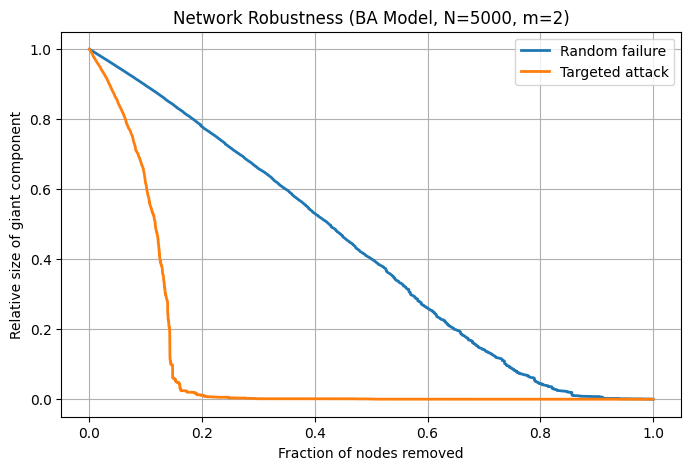

In [45]:
plt.figure(figsize=(8, 5))
plt.plot(frac_r, gc_r, label="Random failure", linewidth=2)
plt.plot(frac_t, gc_t, label="Targeted attack", linewidth=2)

plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative size of giant component")
plt.title(f"Network Robustness (BA Model, N={N}, m={m})")
plt.legend()
plt.grid(True)
plt.show()

## Part 3: Cascading Failures

In [74]:
def compute_initial_loads(G, method="degree"):
    if method == "degree":
        return {node: G.degree(node) for node in G.nodes()}
    elif method == "betweenness":
        bc = nx.betweenness_centrality(G)
        return bc


def redistribute_load(G, failed_node, load_to_redistribute, loads, capacities, method):
    neighbors = list(G.neighbors(failed_node))
    k = len(neighbors)

    if k == 0:
        return
    if method == "equal":
        delta = load_to_redistribute / k
        for v in neighbors:
            loads[v] += delta
    elif method == "proportional_capacity":
        total_cap = sum(capacities[v] for v in neighbors)
        for v in neighbors:
            loads[v] += load_to_redistribute * (capacities[v] / total_cap)

    elif method == "flow":
        bc = nx.betweenness_centrality(G)
        total_bc = sum(bc[v] for v in neighbors)
        if total_bc == 0:
            delta = load_to_redistribute / k
            for v in neighbors:
                loads[v] += delta
        else:
            for v in neighbors:
                loads[v] += load_to_redistribute * (bc[v] / total_bc)


def simulate_cascading_failures(
        G,
        alpha=0.2,
        initial_failure=None,
        load_method="degree",
        redistribution_method="equal"
    ):
    
    G = G.copy()
    failed = set()

    # Li initialization
    loads = compute_initial_loads(G, method=load_method)
    # Ci = (1 + alpha) * Li
    capacities = {node: (1 + alpha) * loads[node] for node in G.nodes()}

    if initial_failure is None:
        f0 = random.choice(list(G.nodes()))
        initial_failures = [f0]
    else:
        initial_failures = [initial_failure]

    queue = deque(initial_failures)

    for f in initial_failures:
        failed.add(f)

    while queue:
        node = queue.popleft()

        if node not in G:
            continue

        load_loss = loads[node]
        neighbors = list(G.neighbors(node))
        redistribute_load(G, node, load_loss, loads, capacities, redistribution_method)
        overloaded = [v for v in G.nodes() if loads[v] > capacities[v] and v not in failed]
        G.remove_node(node)
        for v in overloaded:
            failed.add(v)
            queue.append(v)

    return failed

Testing redistribution method: equal
Testing redistribution method: proportional_capacity


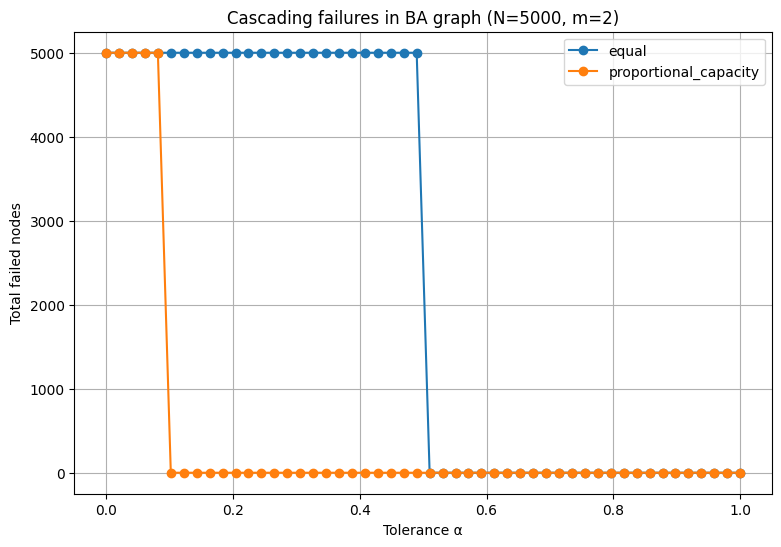

In [128]:
N = 5000
m = 2
G = nx.barabasi_albert_graph(N, m, seed=123)

alphas = list(np.linspace(0, 1, 50))
methods = ["equal", "proportional_capacity"]
results = {method: [] for method in methods}

for method in methods:
    print(f"Testing redistribution method: {method}")
    sizes = []
    for alpha in alphas:
        failed = simulate_cascading_failures(G, initial_failure=0, alpha=alpha, redistribution_method=method, load_method="degree")
        sizes.append(len(failed))
    results[method] = sizes

plt.figure(figsize=(9,6))

for method in methods:
    plt.plot(alphas, results[method], marker='o', label=method)

plt.xlabel("Tolerance α")
plt.ylabel("Total failed nodes")
plt.title(f"Cascading failures in BA graph (N={N}, m={m})")
plt.grid(True)
plt.legend()
plt.show()

## Part 4: Building Robust Networks

In [136]:
with open("powergrid.edges", "r") as f:
    lines = [line for line in f if not line.startswith("%")]

G = nx.parse_edgelist(lines, delimiter=",", nodetype=int)

print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of edges: {G.number_of_edges()}")

Number of nodes: 4941
Number of edges: 6594


In [164]:
rand_res = simulate_robustness(G, attack_type='random')
frac_r, gc_r = zip(*rand_res)

targ_res = simulate_robustness(G, attack_type='targeted')
frac_t, gc_t = zip(*targ_res)

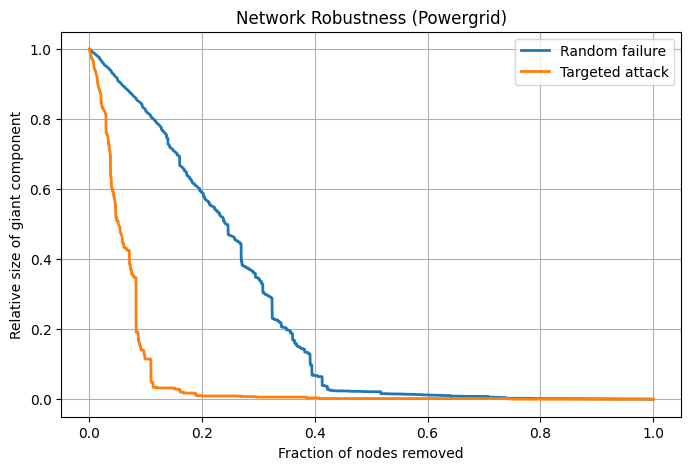

In [178]:
plt.figure(figsize=(8, 5))
plt.plot(frac_r, gc_r, label="Random failure", linewidth=2)
plt.plot(frac_t, gc_t, label="Targeted attack", linewidth=2)
plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative size of giant component")
plt.title(f"Network Robustness (Powergrid)")
plt.legend()
plt.grid(True)
plt.show()

In [180]:
R_orig = np.mean(gc_t)
print(f"R = {R_orig:.2f}")

R = 0.06


In [202]:
c

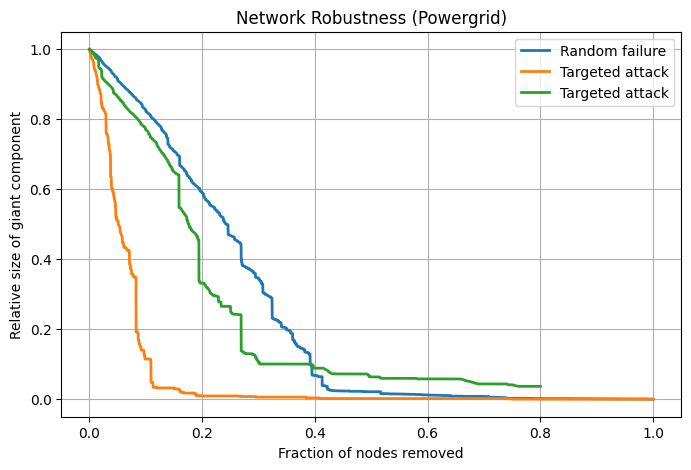

In [203]:
plt.figure(figsize=(8, 5))
plt.plot(frac_r, gc_r, label="Random failure", linewidth=2)
plt.plot(frac_t, gc_t, label="Targeted attack", linewidth=2)
plt.plot(frac_t_prot, gc_t_prot, label="Targeted attack", linewidth=2)
plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative size of giant component")
plt.title(f"Network Robustness (Powergrid)")
plt.legend()
plt.grid(True)
plt.show()

In [206]:
# Compute AUC
auc_orig = np.trapz(gc_t, frac_t)
auc_prot = np.trapz(gc_t_prot, frac_t_prot)

print(f"AUC without protection: {auc_orig:.3f}")
print(f"AUC with top-k protection: {auc_prot:.3f}")

AUC without protection: 0.061
AUC with top-k protection: 0.205


In [214]:
R_orig = np.mean(gc_t)
R_prot = np.mean(gc_t_prot)

perc_improvement = 100 * (R_prot - R_orig) / R_orig

print(f"R without protection: {R_orig:.2f}")
print(f"R with top-k protection: {R_prot:.2f}")
print(f"Percentage improvement in R: {perc_improvement:.2f}%")

R without protection: 0.06
R with top-k protection: 0.26
Percentage improvement in R: 315.30%


In [216]:
def percolation_threshold(frac_removed, gc_fraction, threshold=0.5):
    for f, gc in zip(frac_removed, gc_fraction):
        if gc <= threshold:
            return f
    return 1.0

perc_orig = percolation_threshold(frac_t, gc_t, threshold=0.5)
perc_prot = percolation_threshold(frac_t_prot, gc_t_prot, threshold=0.5)

print(f"Percolation threshold without protection: {perc_orig:.2f}")
print(f"Percolation threshold with top-k protection: {perc_prot:.2f}")
print(f"Change in percolation threshold: {perc_prot - perc_orig:.2f}")

Percolation threshold without protection: 0.05
Percolation threshold with top-k protection: 0.18
Change in percolation threshold: 0.12
